# Template Attack to recover Kappas

In [10]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import os
# Please fill the next variable with the path of the downloaded dataset file.
DATA_DIR = "test_level3-1"
FILENAME = "ipecc_level_3-1_part_0.h5"
PATH_TO_DATA = os.path.join(DATA_DIR,FILENAME)

if not os.path.exists(PATH_TO_DATA):
    print(f"Warning! File not found, please ensure PATH_TO_DATA has been set to the location of a dataset Hdf5 file.")

## Context
Is presented here the template attack performed to recover values of $\kappa$ and $\kappa'$ used during scalar multiplication.

Let us recall that performing the profiling requires knowing values of $\kappa$ and $\kappa'$ which may not be available to the attacker. To obtain those values, the _unsecure_ (debug) mode must be leveraged to recover $\phi$ then compute the $\kappa$'s thanks to the knowledge of the chosen scalar. More details on the derivation of $\kappa's$ from $\phi$ can be found in the dedicated subsection.

This template attack has been mounted to show the relevance of the XY-shuffling countermeasure. Indeed, leakage on $\kappa$'s is visible when Shift-register optional countermeasure only is applied. This leakage vanishes when enabling the XY-shuffling. With this practical attack we show that, if an attacker can use profiled techinques, the leakage can be exploited and thus XY-shuffling countermeasure must be enabled.

## Attack Overview
This notebook allows to perform this attack on the provided dataset. The attack has been splitted into 4 steps that will be detailed but for convenience, 4 python scripts are also available to ease launching attacks from a command line interface (CLI) and enable batch computations (on different datasets for instance).

  1. Compute $\kappa$ and $\kappa'$ values based on $\phi$ values.
  2. Split each trace in subtraces each one corresponding to a single scalar bit processing.
  3. Perform and plot leakage assessment results on the different variables using 2-class SNR.
  4. Actually perform the template attack

## Computation of $\kappa$ and $\kappa'$
In a secure ECC scalar multiplication, the sensitive scalar used (usually denoted by $k$) must be protected and, in particular, the address-bit DPA must be thwarted.

The choice in the proposed accelerator is to use a boolean masking with a random mask denoted by $\phi$. The adaptation of this masking to the used Joye right-to-left ladder has been proposed in [IIT03](https://link.springer.com/chapter/10.1007/978-3-540-45238-6_30) and actually requires two versions of the masked scalar namely
  - $\kappa = k \oplus \phi$,
  - $\kappa' = k \oplus ( 2 (\phi \mod 2^{n-1}) )$.

Said another way, the following relations hold

$$ \phi_0 = \kappa_0 \oplus \kappa'_0 $$
$$ \phi_1 \oplus \phi_0 = \kappa_1 \oplus \kappa'_1 $$
$$ \phi_2 \oplus \phi_1 = \kappa_2 \oplus \kappa'_2 $$
$$ \dots $$

From an attacker perspective, this means that recovering $\kappa$ and $\kappa'$ allows recovering $\phi$ hence the scalar.

As this work goal is to perform an extensive security assessment of *IPECC*, enabling a profiled approach is of outmost importance. While the values of $\kappa$ and $\kappa'$ cannot be obtained from the target but the value of $\phi$  be accessed, using the debugging functionality. Hence, values of $\phi$ can be found in the dataset as inputs and the values for $\kappa's$ can be derived from them and the known scalar values. 

In [11]:
from compute_kappas import compute_kappas

with h5py.File(PATH_TO_DATA, "r") as file_handler:
    scalars = file_handler["inputs/scalar"]
    phis = file_handler["inputs/phi"]

    kappas, kappaPs = compute_kappas(scalars, phis)


Let us check that the equalities actually hold, this will be the opportunity to highlight some details about the dataset.

More precisely, let us notice that the least significant bit of the scalar is not processed similarly to others (see Section 3 of the paper) thus we actually have to make a right shift by 1 position.

Also, the value of $\phi$ in the dataset corresponds to the one obtained from the debug mode of IPECC. It is actually larger than the 256 bits of the curve so we have to mask those first bits.

In [12]:
with h5py.File(PATH_TO_DATA, "r") as file_handler:
    check_def = []
    check_eq1 = []
    check_eq2 = []

    for i in range(len(kappas)):
        kappa = int.from_bytes(kappas[i, :], byteorder="big")
        kappaP = int.from_bytes(kappaPs[i, :], byteorder="big")
        phi = int.from_bytes(file_handler["inputs/phi"][i, :], byteorder="big") & (
            (1 << 256) - 1
        )
        scalar = (
            int.from_bytes(file_handler["inputs/scalar"][i, :], byteorder="big") >> 1
        )

        check_def.append((kappa & 1) == (scalar & 1) ^ (phi & 1))
        check_eq1.append((kappa & 1) ^ (kappaP & 1) == phi & 1)
        check_eq2.append(
            ((kappa >> 1) & 1) ^ ((kappaP >> 1) & 1) == (phi & 1) ^ ((phi >> 1) & 1)
        )
print(f"Check kappa definition: {np.all(check_def)}")
print(f"Check equation (first bit): {np.all(check_eq1)}")
print(f"Check equation (second bit): {np.all(check_eq2)}")

Check kappa definition: True
Check equation (first bit): True
Check equation (second bit): True


To summarize, from the knowledge of $\kappa$ and $\kappa'$, one can recover the value of $\phi$. Knowing $\phi$ and $\kappa$ or $\phi$ and $\kappa'$ or $\kappa$ and $\kappa'$, one can recover the sensitive scalar value.

We thus will perform a leakage assessment on those three variables. For this, we first need to process the curves to obtain subtraces corresponding to a single bit processing.

## Trace Splitting
Each trace corresponds to the scalar processed bit per bit. The first step to peform leakage assessment and profiling is to split each curve in subtraces each corresponding to a single bit processing.

As detailed in Algorithm 3, only $n-2$ (that is 254 here) bits of the scalar are processed in the loop. The `extract_subtraces` function splits each curve in 254 subtraces and computes the corresponding variables bits ($k, \phi, \kappa, \kappa'$). However, the first and last subtraces of each trace are a bit different from the others so we remove them and keep only 252 subtraces. Handling those bits correctly could be an interesting improvement but this is not necessary to exploit the leakage since recovering a significant part of the scalar is usually enough to break the scheme. 

The function takes as inputs the dataset corresponding to the full traces, then a dictionary with the different inputs that we are interested in (we do not look for leakage on the curve base point for instance). Then, a filename for the output dataset must be provided (the size is huge and thus could not be kept in volatile memory on most computers) together with an optional number of traces to process. Then a `refined_filtering` option withdraws some of the subtraces when the peak used for alignment is not correctly positioned (again one may test some alignment method instead). Eventually, a `progession` option enables printing a counter showing the processed curve index.

In [13]:
from splitting import extract_subtraces
with h5py.File(PATH_TO_DATA, "r") as file_handler:
    extract_subtraces(
        traces=file_handler["em_curves"],
        inputs={
            "scalar": file_handler["inputs/scalar"],
            "phi": file_handler["inputs/phi"],
            "kappa": kappas,
            "kappa_prime": kappaPs,
        },
        output_filename=os.path.join(DATA_DIR, "subtraces.h5"),
        refined_filtering=True,
        progression=True,
    )


Writing patterns 
Writing patterns 14131/14131


A file `subtraces.h5` has been created with the mini-traces and the corresponding variable bit values.

In [5]:
with h5py.File(os.path.join(DATA_DIR, "subtraces.h5"), "r") as file_handler:
    file_handler.visititems(lambda x,y: print(f"{x:17s}{y}"))

    print(file_handler["inputs"].dtype)

inputs           <HDF5 dataset "inputs": shape (14131,), type "|V4">
subtraces        <HDF5 dataset "subtraces": shape (14131, 510000), type "<i2">
[('scalar', 'u1', (1,)), ('phi', 'u1', (1,)), ('kappa', 'u1', (1,)), ('kappa_prime', 'u1', (1,))]


We notice the particular type of the `inputs` dataset. It is a composed numpy type which allows a convenient selection using input name as illustrated below.

In [6]:
with h5py.File(os.path.join(DATA_DIR, "subtraces.h5"), "r") as file_handler:
    print(file_handler["inputs"]["scalar"][0:5])

[[1]
 [1]
 [1]
 [0]
 [0]]


## Leakage Assessment
Now that the traces have been split, a leakage assessment on the different variables can be performed.

The `compute_snr` function computes the SNR of variables found in the dataset `inputs` based on subtraces from the `inputs` dataset. The chunk size corresponds to an option of SCALib which allows performing computations providing traces in batch/chunk.

In [7]:
from compute_snr import compute_snr

with h5py.File(os.path.join(DATA_DIR, "subtraces.h5"), "r") as file_handler:

    snrs =  compute_snr(
        file_handler,
        chunk_size= 1000,
    )

Traces shape: (14131, 510000)
Inputs shape: (14131,)
Will process 14131 traces starting from index 0.
Processing subtraces 14000:14131


Obtained results are shown below using the `plot_global` function which plots all results of the results dictionary `snrs` on the same figure.

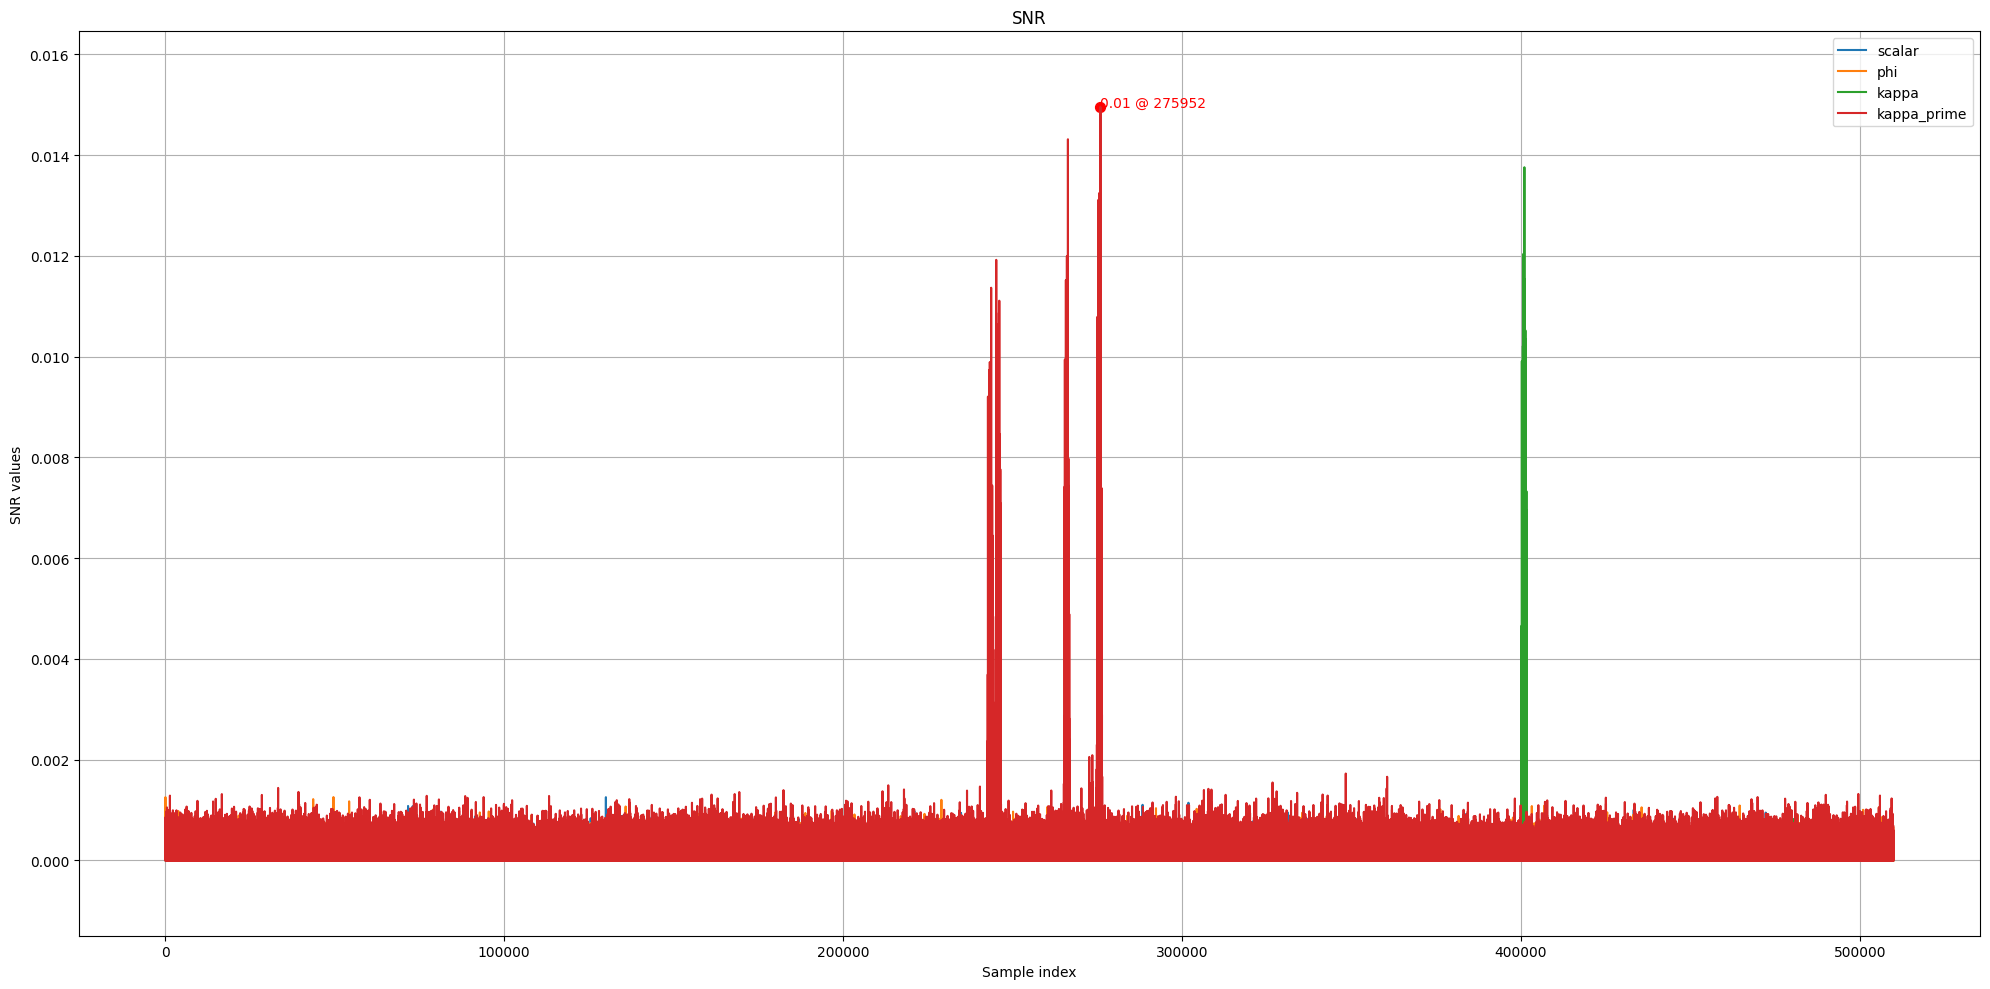

In [8]:
from plot_traces import plot_global

plot_global(
    curves=snrs,
    show_max=True,
    title="SNR",
    y_min = 0,
    y_axis_label="SNR values",
)

## Template Attack
We see that the values of $\kappa'$ bits are leaking in the middle of the subtraces. To show that this leakage is exploitable (and thus confirm the interest of the XY-shufling countermeasure) a template attack is shown below.

The dataset is splitted in 80% of training traces and 20% of attack traces.

The process is as follows.
  1. Compute an SNR on the training traces.
  2. Select PoIs based on the SNR result and a threshold.
  3. Perform LDA on these PoIs (LDA with 2 components).
  4. Compute the template model.
  5. Use the model to predict values on the attack traces.

In [9]:
from template_attack import template_attack


with h5py.File(os.path.join(DATA_DIR, "subtraces.h5"), "r") as file_handler:
    sr = template_attack(
        file_handler, input_target="kappa_prime", learn_ratio=0.8, snr_threshold=0.0009
    )
print(f"Success rate: {sr:.2f}")


1. Perform SNR (to select POIs) 
Traces shape: (14131, 510000)
Inputs shape: (14131,)
Will process 11305 traces starting from index 0.
Processing subtraces 11000:11305
POIs: 4018


2. Build templates 
Processing subtraces 11000:11305

3. Predict 
Processing subtraces 13305:14131
Success rate: 86.91
